# 01 · Exploratory Data Analysis
**Project 18: Water Quality Prediction via Gradient Boosting and Deep Neural Networks**

We compare XGBoost and a small PyTorch MLP for the single continuous target `CCME_Values`. The source contains 2,827,977 records from five countries (1940–2023).

**Read this first:** the source index is calculated from the same eight measurements. This is an index-emulation experiment, not an independent water-quality or safety prediction. The formula audit below checks this directly.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Environment
Tested with Python 3.12. Install the notebook dependencies once in your environment:
```python
%pip install numpy==2.3.4 pandas==2.3.3 scikit-learn==1.7.2 xgboost==3.1.2 torch==2.9.1 matplotlib==3.11.2 joblib==1.6.0 ipykernel
```
Restart the kernel after installation. Run the notebooks in this order: **01_eda → Preprocessing → 02_Model_Application**. Each notebook includes its own implementation, with no project package or scripts.

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / "Datasets").is_dir() else Path.cwd().parent
if not (ROOT / "Datasets").is_dir():
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
DATA = ROOT / "Datasets"
WORK = DATA / "_working"  # Local intermediate files; ignored by Git.
FIGURES = ROOT / "figures"
WORK.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
CSV = WORK / "Combined_dataset.csv"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = [
    "Ammonia",
    "BOD",
    "Dissolved oxygen",
    "Orthophosphate",
    "pH",
    "Temperature",
    "Nitrogen",
    "Nitrate",
]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    Missing/nonfinite values produce NaN rather than silently passing a test.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result

## 2. Load and verify the source
The ZIP is only compression: its CSV is unchanged. Country files must not be appended to the combined dataset.

In [2]:
# The included ZIP contains the unmodified Figshare combined CSV.
# If you deleted the ZIP, the same pinned source can be downloaded again.
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
archive = DATA / "Water_Quality_Dataset.zip"
if not CSV.exists():
    if archive.exists():
        with zipfile.ZipFile(archive) as z:
            with z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                import shutil
                shutil.copyfileobj(src, dst)
    else:
        import urllib.request
        urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
        with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as z:
            z.write(CSV, "Combined_dataset.csv")
assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
raw = pd.read_csv(CSV)
assert set(META + FEATURES + [TARGET, "CCME_WQI"]).issubset(raw.columns)
print(f"Verified source: {len(raw):,} rows × {len(raw.columns)} columns")
display(raw.head())

Verified source: 2,827,977 rows × 14 columns


,Country,Area,Waterbody Type,Date,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),CCME_Values,CCME_WQI
0,Canada,SE649035-145565,River,12-01-1974,0.059248,1.30,8.1500,0.011917,8.07500,9.885,0.343917,11.73155,100.0,Excellent
1,Canada,SE649035-145565,River,12-01-1975,0.039821,1.38,7.8000,0.009417,7.73333,10.150,0.449083,11.82009,100.0,Excellent
2,Canada,SE649035-145565,River,12-01-1976,0.031341,2.23,7.8000,0.011000,7.46667,10.235,0.220750,14.87472,100.0,Excellent
3,Canada,SE649035-145565,River,12-01-1977,0.020501,1.61,8.1500,0.012333,7.78333,11.116,0.572250,15.89293,100.0,Excellent
4,Canada,SE649035-145565,River,12-01-1978,0.020023,1.64,4.3708,0.006182,7.10000,7.068,0.371091,15.22888,100.0,Excellent


## 3. Measurements, units and data quality
Concentrations are labelled mg/L, pH is dimensionless and temperature is labelled °C. Turbidity, conductivity and dissolved solids are absent. The delivered file was already harmonized and imputed upstream, so zero missing cells do not imply complete original measurements.

We flag negative concentrations, pH outside [0,14], nonfinite values and temperature outside [-5,50] °C. The temperature range is a review heuristic. We preserve pollution extremes and do not guess unit conversions or censoring limits.

In [3]:
def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for unit/measurement review, not converted.
    Every input gets a fixed missing/invalid flag, even if train has no missingness.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)

def table_audit(raw):
    reconstructed = source_formula(raw)
    error = np.abs(reconstructed - raw[TARGET].to_numpy())
    q = quality_features(raw)
    numeric = raw[FEATURES].apply(pd.to_numeric, errors="coerce")
    return {
        "raw_rows": len(raw),
        "raw_columns": len(raw.columns),
        "country_counts": raw.Country.value_counts().to_dict(),
        "class_counts": raw.CCME_WQI.value_counts().to_dict(),
        "area_counts_by_country": raw.groupby("Country").Area.nunique().to_dict(),
        "missing_as_delivered": raw.isna().sum().to_dict(),
        "invalid_or_missing_by_feature": q[FEATURES].isna().sum().to_dict(),
        "rows_with_quality_flags": int(q[FEATURES].isna().any(axis=1).sum()),
        "feature_summary": json.loads(numeric.describe().to_json()),
        "most_frequent_reading": {
            col: {
                "value": float(numeric[col].mode().iloc[0]),
                "fraction": float(numeric[col].value_counts(normalize=True).iloc[0]),
            }
            for col in FEATURES
        },
        "formula_audit": {
            "denominator": 12,
            "mae": float(np.nanmean(error)),
            "max_absolute_error": float(np.nanmax(error)),
            "fraction_matching_at_1e_7": float(np.mean(error < 1e-7)),
            "finite_reconstructions": int(np.isfinite(reconstructed).sum()),
        },
        "class_threshold_disagreements": int(
            np.sum(
                pd.cut(
                    raw[TARGET],
                    [-0.001, 45, 65, 80, 95, 100.001],
                    right=False,
                    labels=["Poor", "Marginal", "Fair", "Good", "Excellent"],
                )
                .astype(str)
                .to_numpy()
                != raw.CCME_WQI.to_numpy()
            )
        ),
    }

audit = table_audit(raw)
audit["exact_duplicates_removed"] = int(raw.duplicated().sum())
(WORK / "data_audit.json").write_text(json.dumps(audit, indent=2, allow_nan=False))
print("Exact duplicates:", audit["exact_duplicates_removed"])
print("Missing cells as delivered:", int(raw.isna().sum().sum()))
print("Rows with flagged measurements:", audit["rows_with_quality_flags"])
display(raw[FEATURES].describe().T)
display(pd.Series(audit["invalid_or_missing_by_feature"], name="Flagged readings").to_frame())

Exact duplicates: 9971
Missing cells as delivered: 0
Rows with flagged measurements: 6468


,count,mean,std,min,25%,50%,75%,max
Ammonia (mg/l),2827977.0,1.171360,5.668927,-0.005,0.030,0.055,0.317,200.0
Biochemical Oxygen Demand (mg/l),2827977.0,4.886554,16.413632,-2.000,1.600,2.700,2.830,255.0
Dissolved Oxygen (mg/l),2827977.0,10.007978,1.851052,0.000,9.860,10.200,11.000,20.0
Orthophosphate (mg/l),2827977.0,0.710466,2.089436,-0.004,0.040,0.107,0.227,100.0
pH (ph units),2827977.0,7.735931,0.494687,-1.000,7.550,7.780,8.000,30.0
Temperature (cel),2827977.0,11.839341,5.010197,-5.260,8.990,11.460,14.200,98.0
Nitrogen (mg/l),2827977.0,5.209531,6.200423,0.000,0.780,4.000,6.320,46.0
Nitrate (mg/l),2827977.0,4.766794,6.073781,0.000,1.173,4.500,4.940,155.0


,Flagged readings
Ammonia (mg/l),2
Biochemical Oxygen Demand (mg/l),2
Dissolved Oxygen (mg/l),0
Orthophosphate (mg/l),10
pH (ph units),505
Temperature (cel),5980
Nitrogen (mg/l),0
Nitrate (mg/l),0


## 4. Verify what the target means
The released single-row formula uses eight upper-bound objectives `[0.5, 6, 14, 0.05, 8.5, 25, 20, 45]`, a denominator of 12 and `F2 = F1`. The denominator is inferred by exact agreement with the release. The upstream harmonization notebook uses `len(df.columns)`, so the frame at execution affects its calculation.

For each row, count failed objectives, sum positive relative excursions, calculate F1/F3 and combine them as shown in `source_formula` above. This differs from official CCME WQI, which requires an assessment period and appropriate objectives. Dissolved oxygen and pH should not be interpreted as universally upper-only criteria.

The audit runs on original measurements before applying our quality masks. `CCME_WQI` is excluded from all model inputs and is used only for descriptive subgroup evaluation.

In [4]:
display(pd.Series(audit["formula_audit"], name="Full-source formula audit").to_frame())
assert audit["formula_audit"]["fraction_matching_at_1e_7"] == 1.0
print("Every released label reconstructs from its predictors within 1e-7.")

Every released label reconstructs from its predictors within 1e-7.


,Full-source formula audit
denominator,1.200000e+01
mae,1.220143e-15
max_absolute_error,2.842171e-14
fraction_matching_at_1e_7,1.000000e+00
finite_reconstructions,2.827977e+06


## 5. Explore representation and relationships
All charts below are exported to the repository’s `figures/` folder.

Matplotlib is building the font cache; this may take a moment.


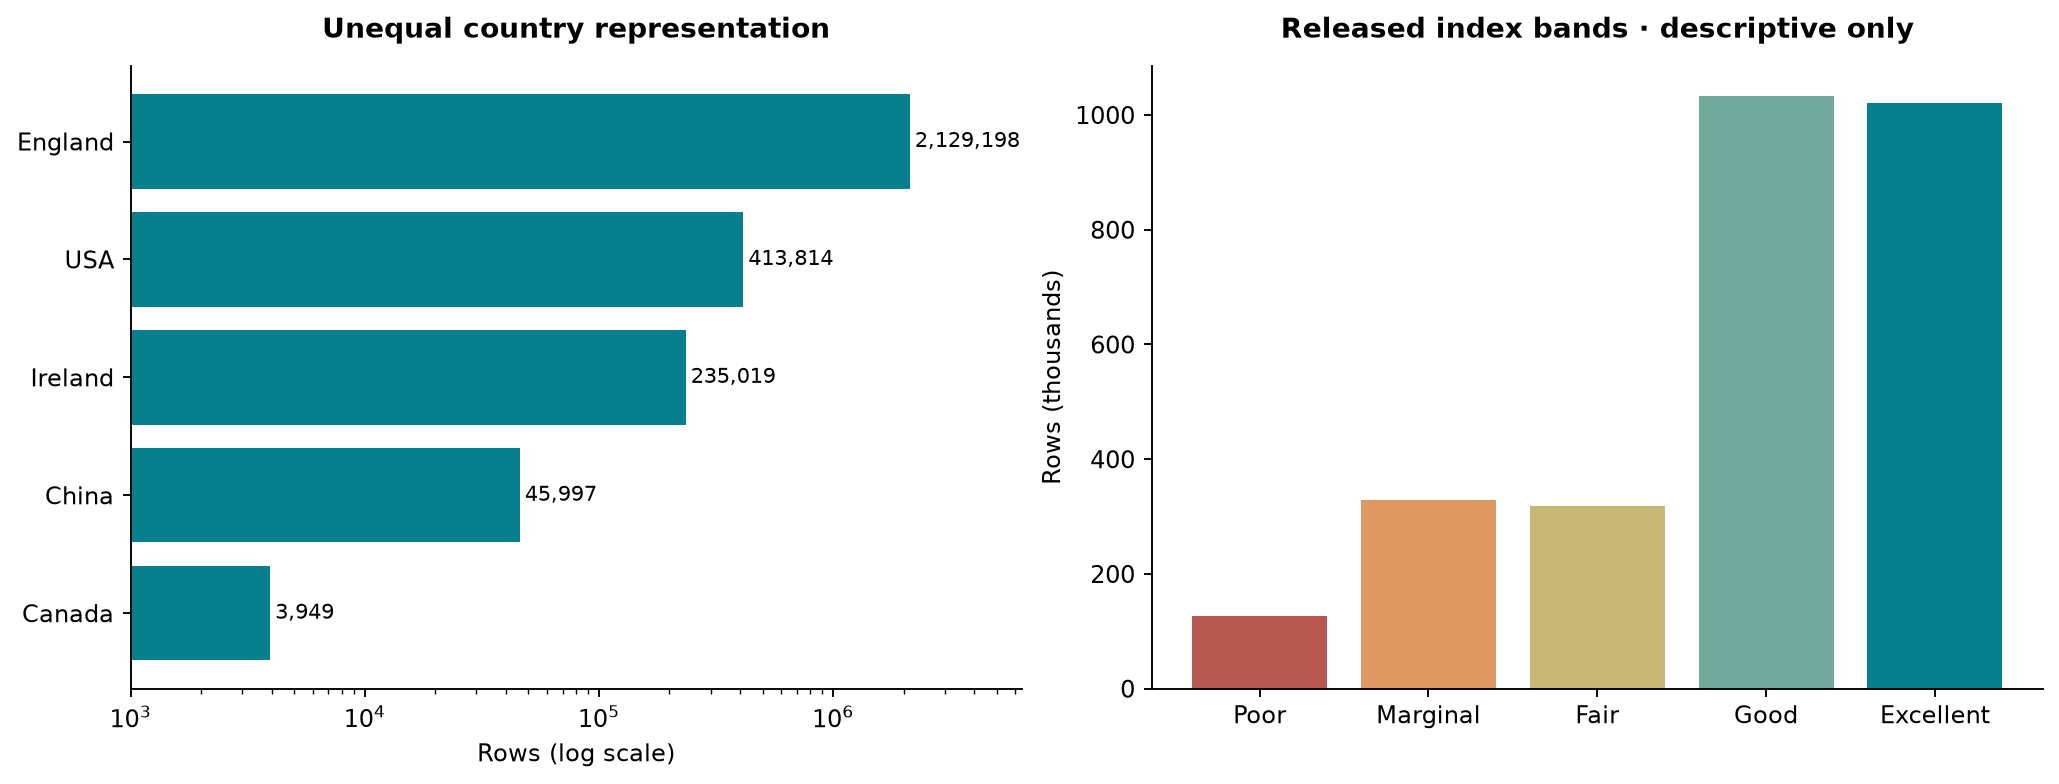

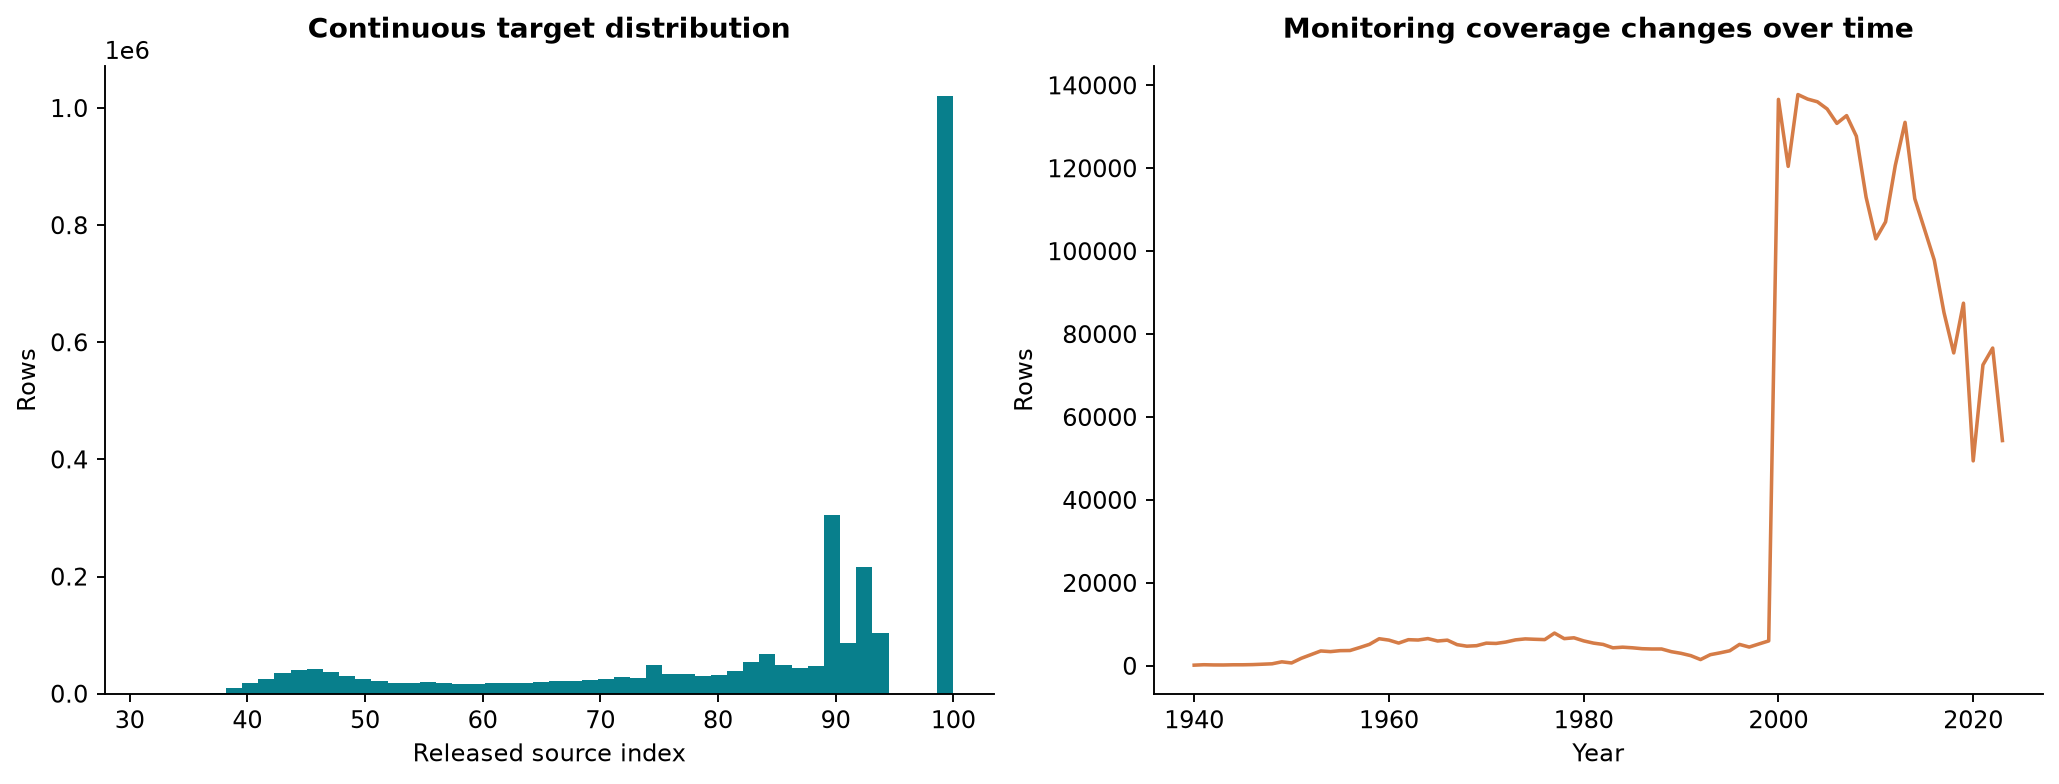

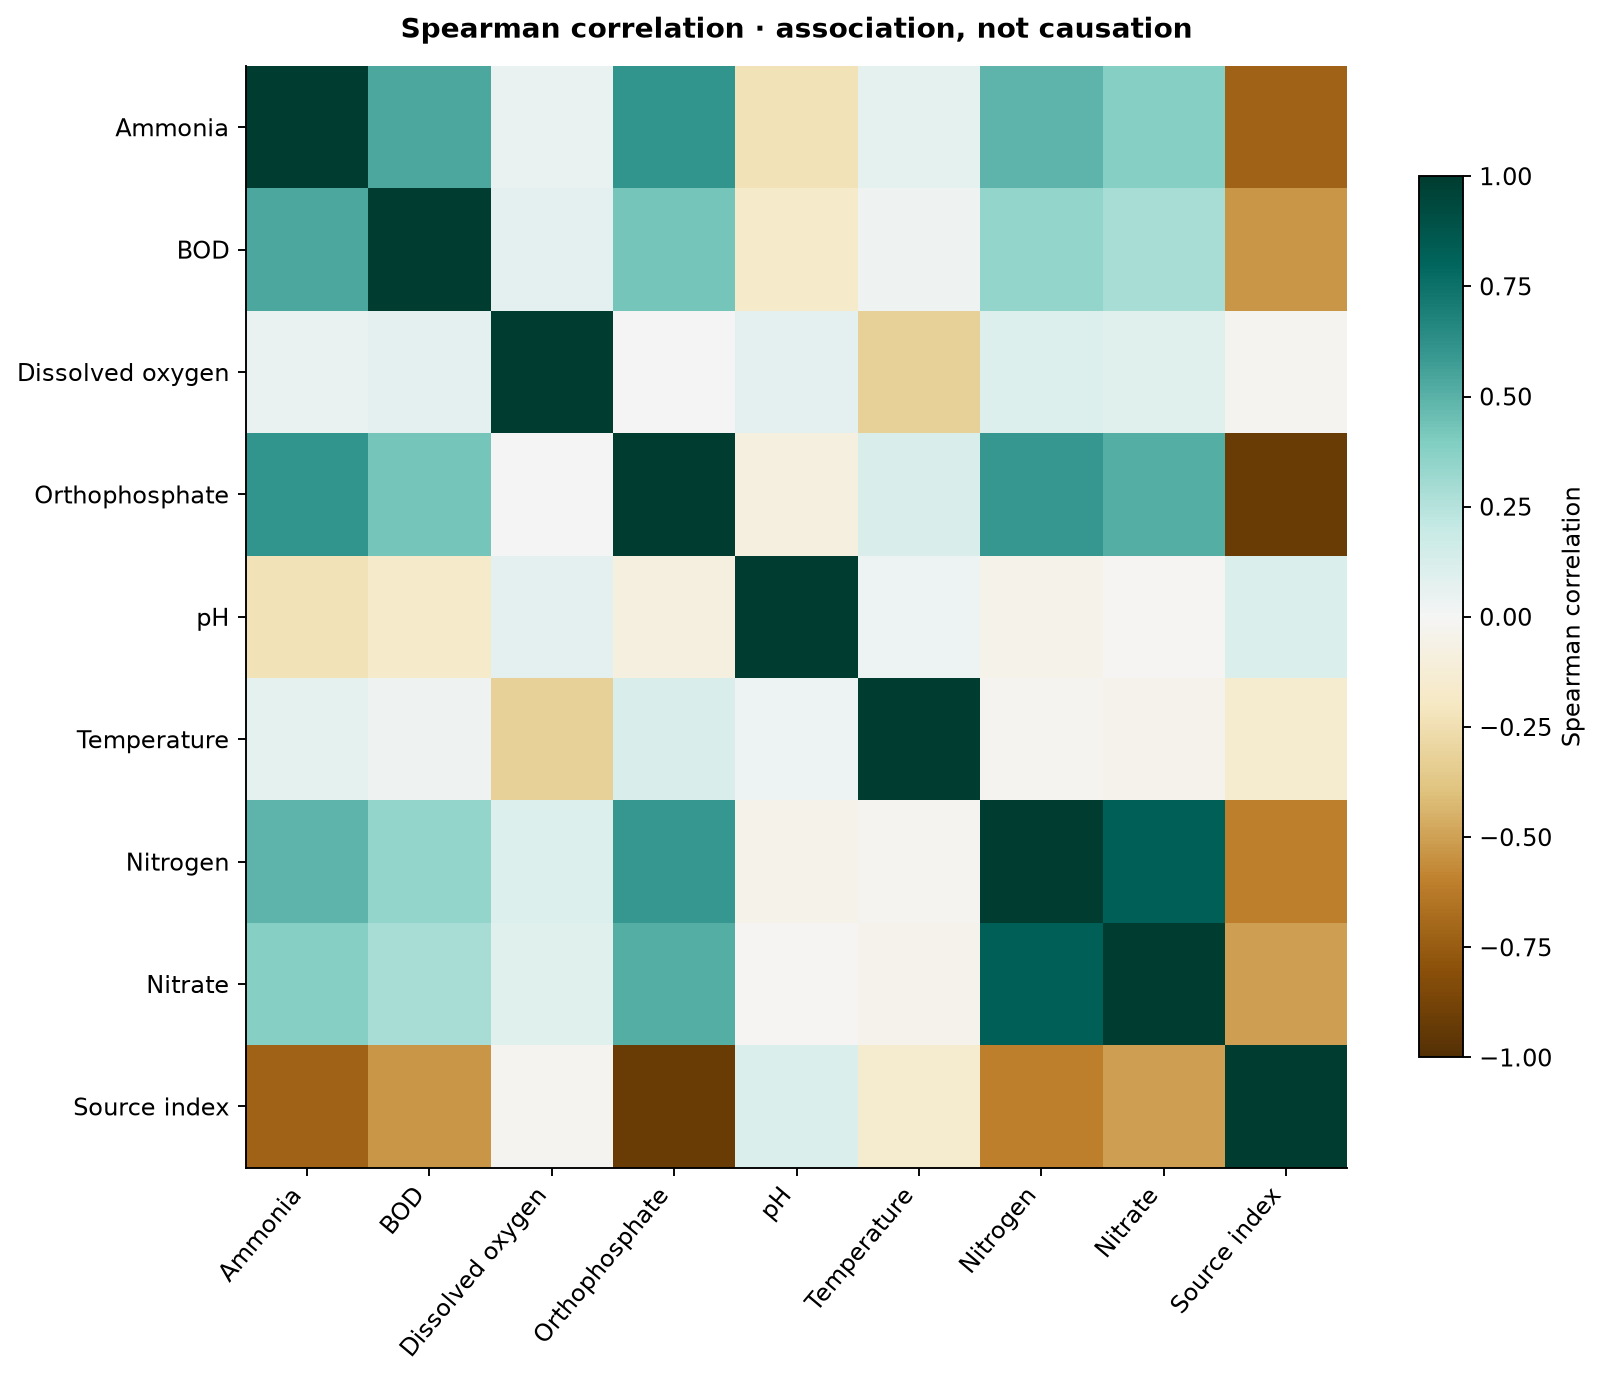

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 12})
def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
countries = raw.Country.value_counts().sort_values()
axes[0].barh(countries.index, countries.values, color="#087f8c")
axes[0].set(xscale="log", xlabel="Rows (log scale)", title="Unequal country representation")
for i, count in enumerate(countries.values):
    axes[0].text(count * 1.05, i, f"{count:,}", va="center", fontsize=9)
axes[0].set_xlim(1000, countries.max() * 3)
bands = raw.CCME_WQI.value_counts().reindex(["Poor", "Marginal", "Fair", "Good", "Excellent"])
axes[1].bar(bands.index, bands.values / 1000, color=["#b55750", "#df9862", "#c6b775", "#71a99d", "#087f8c"])
axes[1].set(ylabel="Rows (thousands)", title="Released index bands · descriptive only")
show_figure(fig, "data_overview.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
years = pd.to_datetime(raw.Date, format="%d-%m-%Y").dt.year
axes[0].hist(raw[TARGET], bins=50, color="#087f8c")
axes[0].set(xlabel="Released source index", ylabel="Rows", title="Continuous target distribution")
years.value_counts().sort_index().plot(ax=axes[1], color="#d57c47")
axes[1].set(xlabel="Year", ylabel="Rows", title="Monitoring coverage changes over time")
show_figure(fig, "target_and_time.png")

corr = raw[FEATURES + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
labels = SHORT_NAMES + ["Source index"]
ax.set_xticks(range(len(labels)), labels, rotation=50, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Spearman correlation · association, not causation")
fig.colorbar(im, ax=ax, label="Spearman correlation", shrink=.8)
show_figure(fig, "feature_correlations.png")

## Findings and next step
England dominates the records. Coverage varies by year and country. Correlations and later feature importance partly reflect how the target was constructed. High model accuracy will therefore measure formula emulation.

Continue with **Preprocessing.ipynb** for duplicate removal, chronological partitions and training-only transforms.

Sources: [Karim et al., Figshare v2](https://doi.org/10.6084/m9.figshare.27800394.v2), [CCME WQI manual](https://ccme.ca/en/res/wqimanualen.pdf). Data are reused under CC BY 4.0 with this attribution.